# Новый алгоритм назначения курьеров: оценка эффекта методом Difference-in-Differences

**Сессионное задание по курсу A/B-тестирования.**

## Контекст

Сервис экспресс-доставки продуктов работает в 20 городах. Команда логистики сделала новый алгоритм,
который назначает курьеров на заказы и рассчитывает обещанное время доставки (ETA).
Алгоритм показывает пользователю более короткий и точный ETA, и ожидается, что из-за этого
**больше пользователей, открывших приложение, оформят заказ**.

4 мая 2026 алгоритм включили сразу во всём городе в 8 пилотных городах. Пилотные города выбирал бизнес:
туда попали 3 из 6 крупных городов, 3 из 7 средних и 2 из 7 малых. Остальные 12 городов работают по-старому.

| Роль | Метрика | Уровень |
|---|---|---|
| Основная | Конверсия активного пользователя в заказ: `orders / active_users`, % | город × день |
| Guardrail | Доля опоздавших заказов (доставлено позже обещанного ETA), % | город × день |
| Guardrail | Доля отменённых заказов, % | город × день |
| Guardrail | Среднее время доставки, мин | город × день |
| Guardrail | Число активных пользователей (DAU), log | город × день |

**Данные** сгенерированы скриптом `data_generation/generate_data.py` (seed = 20260504): панель «город × день»
со 2 марта по 28 июня 2026 (9 недель до запуска, 8 недель после) и выборка пользователей по городам.
Что именно заложено в генератор, в анализе считается неизвестным: всё нужно найти по данным.

## Структура
0. Подготовка: загрузка и качество данных
1. Разведочный анализ и проверка предпосылок (тренды, сезонность, баланс, параллельные тренды, плацебо)
2. Выбор метода причинного вывода и альтернативный дизайн
3. Оценка эффекта: DiD, доверительные интервалы, event study, чувствительность, эффект по стратам
4. Guardrail-анализ
5. Продуктовый вывод
6. Бонус: контроль сезонности, synthetic control, сравнение с наивными оценками

Уровень значимости везде α = 0.05.

In [1]:
import warnings
from itertools import combinations, product
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import patsy
import seaborn as sns
import statsmodels.formula.api as smf
from scipy import optimize, stats
from statsmodels.stats.multitest import multipletests

SEED = 4051
ALPHA = 0.05
LAUNCH = pd.Timestamp("2026-05-04")
HOLIDAYS = pd.to_datetime(["2026-05-01", "2026-05-02", "2026-05-03",
                           "2026-05-09", "2026-05-10", "2026-05-11"])
STRATA = ["large", "medium", "small"]

# Локально данные лежат в data/, в Colab скачиваются из репозитория
DATA_DIR = Path("data")
RAW_URL = "https://raw.githubusercontent.com/JuraMe/AB-Session-project/main/data/"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"control": "#4C72B0", "treated": "#DD8452"}
rng = np.random.default_rng(SEED)
# При кластеризации по ~20 городам ковариационная матрица сотен фиксированных эффектов вырождена,
# и SE самих фиксированных эффектов численно получаются NaN. На SE интересующего коэффициента это не влияет.
warnings.filterwarnings("ignore", message="invalid value encountered in sqrt")


def in_notebook() -> bool:
    """True, если код выполняется в Jupyter/IPython."""
    try:
        get_ipython  # noqa: F821
        return True
    except NameError:
        return False


if not in_notebook():
    matplotlib.use("Agg")  # в обычном скрипте графики только сохраняются в figures/


def show(fig, name):
    """Сохранить график в figures/ и показать его (в ноутбуке) или закрыть (в скрипте)."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight")
    if in_notebook():
        plt.show()
    else:
        plt.close(fig)


def read_data(name):
    path = DATA_DIR / name
    return pd.read_csv(path if path.exists() else RAW_URL + name)


def smd(a, b):
    """Стандартизованная разница средних: |SMD| > 0.1 считаем заметным дисбалансом."""
    return (np.mean(a) - np.mean(b)) / np.sqrt((np.var(a, ddof=1) + np.var(b, ddof=1)) / 2)

## 0. Загрузка и качество данных

In [2]:
raw = read_data("city_daily.csv")
users = read_data("users_sample.csv")
raw["date"] = pd.to_datetime(raw["date"])

print(f"Панель: {raw.shape[0]} строк, {raw['city'].nunique()} городов, "
      f"{raw['date'].min():%d.%m.%Y} – {raw['date'].max():%d.%m.%Y}")
print(f"Пользователей в выборке: {len(users)}")
print(f"Пропуски в ячейках: {int(raw.isna().sum().sum())}, "
      f"дубли (город, дата): {int(raw.duplicated(['city', 'date']).sum())}")

# 1) Полнота панели: у каждого города должна быть запись на каждый день
n_days = raw["date"].nunique()
days_per_city = raw.groupby("city")["date"].nunique()
print(f"\nОжидается {n_days} дней на город. Неполные города:")
print(days_per_city[days_per_city < n_days])
full_grid = pd.MultiIndex.from_product([raw["city"].unique(), raw["date"].unique()], names=["city", "date"])
missing = full_grid.difference(raw.set_index(["city", "date"]).index).to_frame(index=False)
print(missing.groupby("city")["date"].agg(["min", "max", "count"]))

# 2) Выбросы: конверсия города в день против скользящей медианы этого города (робастный z-score)
raw["conv"] = raw["orders"] / raw["active_users"]
raw = raw.sort_values(["city", "date"])
med = raw.groupby("city")["conv"].transform(lambda s: s.rolling(15, center=True, min_periods=5).median())
resid = raw["conv"] - med
mad = resid.groupby(raw["city"]).transform(lambda s: (s - s.median()).abs().median())
raw["robust_z"] = resid / (1.4826 * mad)
outliers = raw[raw["robust_z"].abs() > 6]
print("\nВыбросы (|robust z| > 6):")
print(outliers[["date", "city", "active_users", "orders", "conv", "robust_z"]])

Панель: 2375 строк, 20 городов, 02.03.2026 – 28.06.2026
Пользователей в выборке: 60000
Пропуски в ячейках: 0, дубли (город, дата): 0

Ожидается 119 дней на город. Неполные города:
city
S07    114
Name: date, dtype: int64
            min        max  count
city                             
S07  2026-03-23 2026-03-27      5

Выбросы (|robust z| > 6):
          date city  active_users  orders   conv  robust_z
401 2026-04-15  L04         60160   15530 0.2581   20.4532


**Качество данных:**
* Пропусков в ячейках и дублей нет, но **панель неполная**: у контрольного города S07 нет записей за 5 дней подряд
  (23–27 марта). Похоже на сбой логирования. Строки не восстанавливаем: модели с фиксированными эффектами
  работают с несбалансированной панелью, а 5 дней из 119 в контрольном городе на оценку почти не влияют.
* В контрольном городе L04 за 15 апреля конверсия в два раза выше обычной (robust z ≈ 20),
  при этом число активных пользователей нормальное. Это дубли заказов в логах, а не настоящий всплеск:
  отмены и опоздания задвоены так же. **Этот день исключаем.**

In [3]:
df = raw[raw["robust_z"].abs() <= 6].copy()
df["post"] = (df["date"] >= LAUNCH).astype(int)
df["tp"] = df["treated"] * df["post"]                        # индикатор «пилотный город после запуска»
df["group"] = np.where(df["treated"] == 1, "treated", "control")
df["conv_pp"] = 100 * df["orders"] / df["active_users"]      # основная метрика, %
df["late_pp"] = 100 * df["late_orders"] / df["orders"]
df["cancel_pp"] = 100 * df["cancelled_orders"] / df["orders"]
df["log_dau"] = np.log(df["active_users"])
df["aov"] = df["revenue"] / df["orders"]
df["t"] = (df["date"] - df["date"].min()).dt.days
df["weekday"] = df["date"].dt.weekday
df["holiday"] = df["date"].isin(HOLIDAYS).astype(int)
df["rel_day"] = (df["date"] - LAUNCH).dt.days
df["rel_week"] = df["rel_day"] // 7                          # -9 ... +7, неделя 0 начинается в день запуска
df["week"] = df["date"].dt.to_period("W-SUN").dt.start_time
df["stratum_date"] = df["stratum"] + "_" + df["date"].dt.strftime("%m%d")
df["stratum_week"] = df["stratum"] + "_" + df["week"].dt.strftime("%m%d")
# Эффекты города и эффекты «страта × дата» линейно зависимы (сумма городов страты = сумма дат страты).
# Поэтому для одного «опорного» города в каждой страте дамми города не заводим: city_fe = "_ref".
REF_CITIES = df.groupby("stratum")["city"].min()
df["city_fe"] = np.where(df["city"].isin(REF_CITIES), "_ref", df["city"])
FE_MAIN = "C(city_fe, Treatment('_ref')) + C(stratum_date)"

city_info = df.groupby("city")[["stratum", "treated"]].first()
print(pd.crosstab(city_info["stratum"], city_info["treated"].map({0: "control", 1: "treated"}), margins=True))
print(f"\nСтрок после очистки: {len(df)}")

treated  control  treated  All
stratum                       
large          3        3    6
medium         4        3    7
small          5        2    7
All           12        8   20

Строк после очистки: 2374


## 1. Разведочный анализ и проверка предпосылок

### 1.1 Тренды по городам во времени

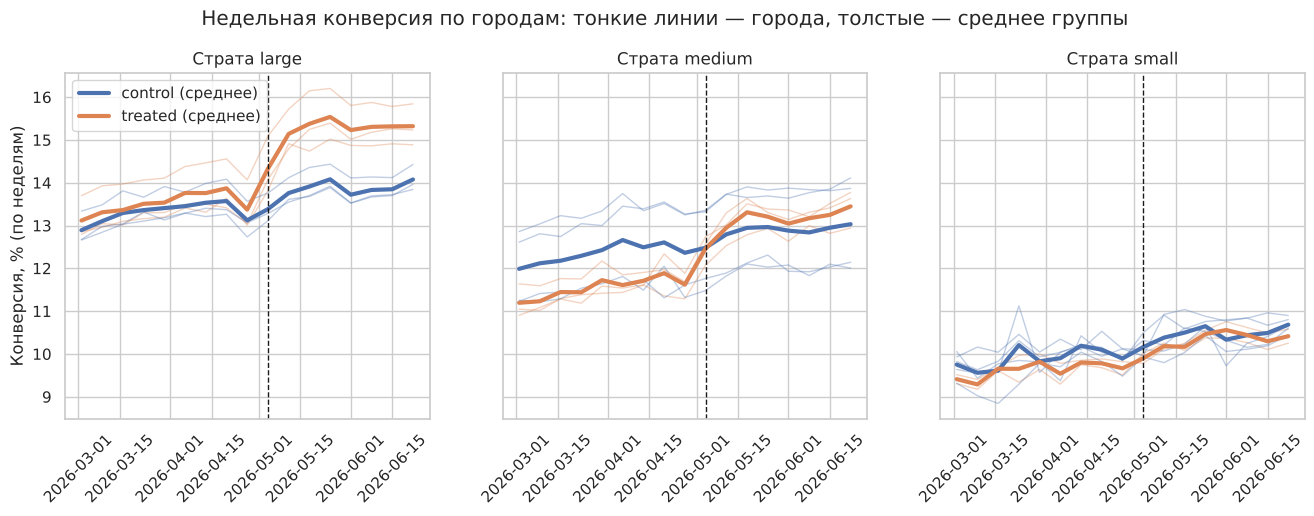

In [4]:
weekly = (df.groupby(["week", "city", "stratum", "group"], as_index=False)[["orders", "active_users"]].sum())
weekly["conv_pp"] = 100 * weekly["orders"] / weekly["active_users"]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, s in zip(axes, STRATA):
    w = weekly[weekly["stratum"] == s]
    for city, g in w.groupby("city"):
        grp = g["group"].iloc[0]
        ax.plot(g["week"], g["conv_pp"], color=PALETTE[grp], alpha=0.35, lw=1)
    agg = w.groupby(["week", "group"])["conv_pp"].mean().unstack()
    for grp in ["control", "treated"]:
        ax.plot(agg.index, agg[grp], color=PALETTE[grp], lw=3, label=f"{grp} (среднее)")
    ax.axvline(LAUNCH, color="k", ls="--", lw=1)
    ax.set_title(f"Страта {s}")
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Конверсия, % (по неделям)")
axes[0].legend(loc="upper left")
fig.suptitle("Недельная конверсия по городам: тонкие линии — города, толстые — среднее группы", y=1.02)
show(fig, "01_trends_by_city")

* Уровни конверсии сильно различаются по стратам: крупные города ≈ 13–14%, средние ≈ 11–12.5%, малые ≈ 9.5–10%.
  Среди пилотных городов доля крупных больше (3 из 8 против 3 из 12 в контроле), а в средней страте пилотные города
  изначально ниже контрольных. Поэтому **простое сравнение пилотных и контрольных городов смещено**
  уже из-за состава групп.
* Внутри каждой страты до запуска линии пилотных и контрольных городов идут почти параллельно.
  После 4 мая в крупных и средних городах линия пилотных городов уходит вверх, в малых городах разрыв почти не меняется.
* Во всех городах есть общий рост в марте–апреле, провал в начале мая (праздники) и плато в июне.
  Это общие для всех городов шоки, именно их DiD и вычитает.

### 1.2 Сезонность: дни недели и праздники

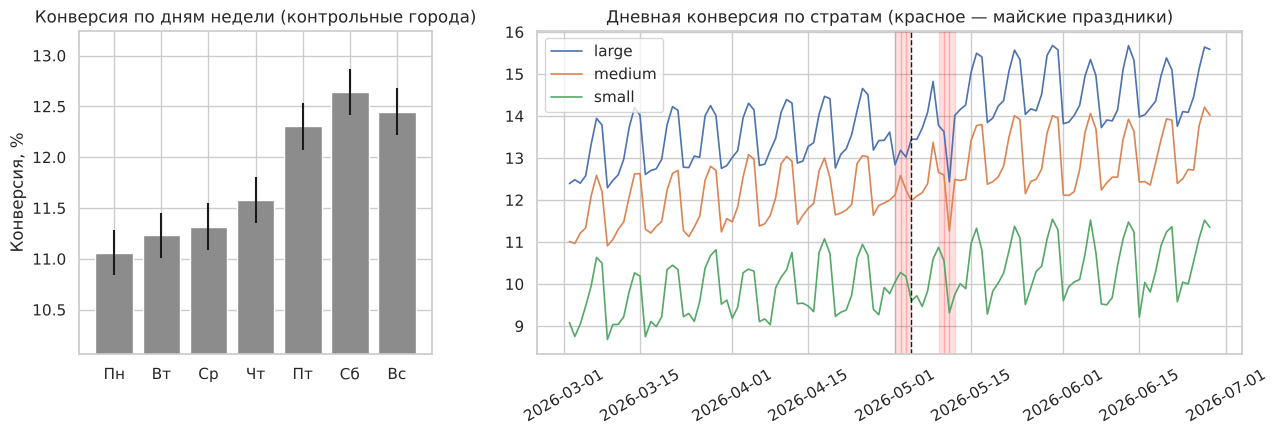

                            эффект праздника, п.п.  p_value
holiday:C(stratum)[large]                  -1.3771   0.0000
holiday:C(stratum)[medium]                 -0.8109   0.0000
holiday:C(stratum)[small]                  -0.3410   0.0098

F-тест на равенство дней недели: p = 4.7e-287


In [5]:
ctrl_all = df[df["treated"] == 0]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 2]})
wd = ctrl_all.groupby("weekday")["conv_pp"].agg(["mean", "sem"])
axes[0].bar(["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"], wd["mean"], yerr=1.96 * wd["sem"], color="#8C8C8C")
axes[0].set_ylim(wd["mean"].min() - 1, wd["mean"].max() + 0.6)
axes[0].set_title("Конверсия по дням недели (контрольные города)")
axes[0].set_ylabel("Конверсия, %")

daily = df.groupby(["date", "stratum"])["conv_pp"].mean().unstack()
for s in STRATA:
    axes[1].plot(daily.index, daily[s], lw=1.2, label=s)
for h in HOLIDAYS:
    axes[1].axvspan(h, h + pd.Timedelta(days=1), color="red", alpha=0.12)
axes[1].axvline(LAUNCH, color="k", ls="--", lw=1)
axes[1].set_title("Дневная конверсия по стратам (красное — майские праздники)")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)
show(fig, "02_seasonality")

# Насколько праздники «бьют» по разным стратам: регрессия на контрольных городах
hol = smf.ols("conv_pp ~ holiday:C(stratum) + C(weekday) + C(city) + t", data=ctrl_all).fit(
    cov_type="cluster", cov_kwds={"groups": ctrl_all["city"]})
print(hol.params.filter(like="holiday").to_frame("эффект праздника, п.п.").assign(p_value=hol.pvalues.filter(like="holiday")))
anova_wd = smf.ols("conv_pp ~ C(weekday) + C(city) + t", data=ctrl_all).fit()
print(f"\nF-тест на равенство дней недели: p = {anova_wd.f_test([c + ' = 0' for c in anova_wd.params.index if 'weekday' in c]).pvalue:.2g}")

* **Недельная сезонность сильная:** в субботу конверсия в среднем на 1.6 п.п. выше, чем в понедельник
  (12.6% против 11.0%, F-тест p ≈ 0). Поэтому в моделях нужны фиксированные эффекты дня (или хотя бы дня недели), а окна оценки
  должны состоять из целых недель.
* **Майские праздники** снижают конверсию, и **сильнее в крупных городах**: −1.38 п.п. в крупных, −0.81 в средних
  и −0.34 в малых (все p < 0.01).
  Первые праздники (1–3 мая) попадают в пред-период, вторые (9–11 мая) — в пост-период.
  Так как в пилоте перевес крупных городов, общий для всех городов эффект даты этот шок вычтет не полностью.
  Поэтому в основной спецификации используем **фиксированные эффекты «страта × дата»**: каждый пилотный город
  сравнивается с контрольными городами своей страты в тот же день.

### 1.3 Баланс между пилотными и контрольными городами до внедрения
DiD не требует, чтобы уровни метрик совпадали. Но сильный дисбаланс по пользователям — сигнал, что города
могут развиваться по-разному. Поэтому проверяем баланс и в целом, и внутри страт.

Города, средние за пред-период (n = 8 vs 12):
             treated    control     SMD  Welch p  Mann–Whitney p
метрика                                                         
dau       30177.5238 20477.2641  0.4118   0.3867          0.2083
conv_pp      11.7827    11.5394  0.1482   0.7503          0.9101
late_pp       7.3926     7.4569 -0.0879   0.8496          0.8506
cancel_pp     2.3720     2.5537 -0.7139   0.1536          0.1813
delivery     25.5328    25.3674  0.0574   0.9009          1.0000
aov        1355.8814  1336.7040  0.2599   0.5826          0.8506

SMD по пользователям (treated − control), пред-период:
                 все города  внутри large  внутри medium  внутри small
age                 -0.0592       -0.0353         0.0056        0.0102
tenure_months        0.0493        0.0298         0.0188       -0.0076
is_ios               0.0295       -0.0316         0.0119        0.0114
orders_last_30d      0.0318       -0.0090        -0.0159       -0.0140
is_new               0.

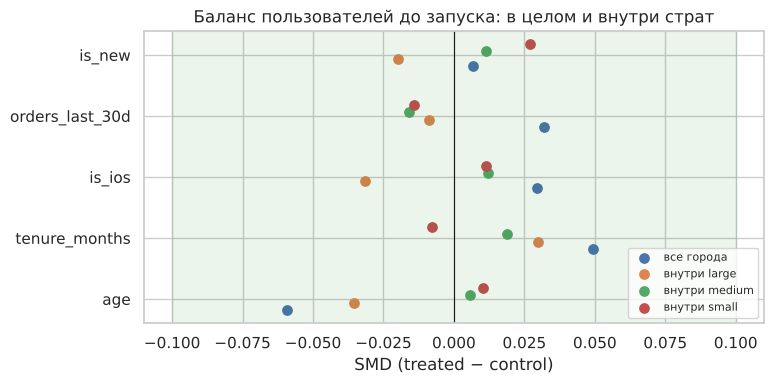

In [6]:
pre = df[df["post"] == 0]
city_pre = pre.groupby("city").agg(stratum=("stratum", "first"), treated=("treated", "first"),
                                    dau=("active_users", "mean"), conv_pp=("conv_pp", "mean"),
                                    late_pp=("late_pp", "mean"), cancel_pp=("cancel_pp", "mean"),
                                    delivery=("avg_delivery_min", "mean"), aov=("aov", "mean"))
rows = []
for col in ["dau", "conv_pp", "late_pp", "cancel_pp", "delivery", "aov"]:
    a, b = city_pre.loc[city_pre.treated == 1, col], city_pre.loc[city_pre.treated == 0, col]
    rows.append({"метрика": col, "treated": a.mean(), "control": b.mean(), "SMD": smd(a, b),
                 "Welch p": stats.ttest_ind(a, b, equal_var=False).pvalue,
                 "Mann–Whitney p": stats.mannwhitneyu(a, b).pvalue})
print("Города, средние за пред-период (n = 8 vs 12):")
print(pd.DataFrame(rows).set_index("метрика"))

# Пользовательский уровень: SMD в целом и внутри страт (пред-период)
u_pre = users[users["period"] == "pre"]
covs = ["age", "tenure_months", "is_ios", "orders_last_30d", "is_new"]
bal = pd.DataFrame({
    "все города": [smd(u_pre.loc[u_pre.treated == 1, c], u_pre.loc[u_pre.treated == 0, c]) for c in covs],
    **{f"внутри {s}": [smd(u_pre.loc[(u_pre.treated == 1) & (u_pre.stratum == s), c],
                           u_pre.loc[(u_pre.treated == 0) & (u_pre.stratum == s), c]) for c in covs]
       for s in STRATA},
}, index=covs)
print("\nSMD по пользователям (treated − control), пред-период:")
print(bal)

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, colname in enumerate(bal.columns):
    ax.scatter(bal[colname], np.arange(len(covs)) + (i - 1.5) * 0.12, label=colname, s=45)
ax.axvspan(-0.1, 0.1, color="green", alpha=0.08)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(len(covs)), covs)
ax.set_xlabel("SMD (treated − control)")
ax.set_title("Баланс пользователей до запуска: в целом и внутри страт")
ax.legend(fontsize=8, loc="lower right")
show(fig, "03_balance")

* **На уровне городов** есть заметный дисбаланс: пилотные города в среднем в 1.5 раза крупнее по DAU (SMD = 0.41),
  с чуть выше конверсией (SMD = 0.15) и ниже долей отмен (SMD = −0.71). Тесты незначимы (p > 0.15),
  но это из-за малого числа городов (8 против 12), а не из-за отсутствия различий: |SMD| > 0.1.
  Это следствие отбора пилота бизнесом: туда чаще брали крупные города. **Случайного распределения городов не было.**
* **На уровне пользователей** различий нет: и в целом, и внутри каждой страты все |SMD| < 0.1
  (возраст, стаж, iOS, частота заказов, доля новых). То есть пилотные города отличаются размером,
  но не составом аудитории.
* Для DiD важна не равенство уровней, а одинаковая динамика. Дисбаланс по размеру города учитываем,
  сравнивая города внутри своей страты (эффекты «страта × дата»).

### 1.4 Стабильность состава (аналог SRM для гео-эксперимента)
В гео-эксперименте нет «долей групп», но есть похожий риск: если после запуска в пилотных городах изменился
состав или число пользователей, сравнение до/после смешает эффект алгоритма и смену аудитории.
Проверяем: (1) долю DAU пилотных городов до и после запуска, (2) DiD по составу пользователей.

In [7]:
share = df.groupby(["post", "group"])["active_users"].sum().unstack()
share["доля treated"] = share["treated"] / share.sum(axis=1)
print(share)
# Доля DAU пилотных городов по дням: при отсутствии влияния алгоритма на аудиторию она не меняется.
# Единица анализа — день (а не пользователе-день): DAU одного дня не являются независимыми испытаниями,
# поэтому классический хи-квадрат SRM на миллионах пользователе-дней здесь некорректен.
day_share = (df.pivot_table(index="date", columns="group", values="active_users", aggfunc="sum")
             .assign(share=lambda x: x["treated"] / (x["treated"] + x["control"])))
day_share["post"] = (day_share.index >= LAUNCH).astype(int)
s_pre, s_post = day_share.loc[day_share.post == 0, "share"], day_share.loc[day_share.post == 1, "share"]
p_srm = stats.ttest_ind(s_post, s_pre, equal_var=False).pvalue
print(f"\nДоля DAU пилотных городов по дням: до {s_pre.mean():.4f}, после {s_post.mean():.4f}; "
      f"Welch p = {p_srm:.3f}, Mann–Whitney p = {stats.mannwhitneyu(s_post, s_pre).pvalue:.3f}")

comp_rows = []
for c in covs:
    m = smf.ols(f"{c} ~ treated * C(period) + C(stratum)", data=users).fit(
        cov_type="cluster", cov_kwds={"groups": users["city"]})
    term = [k for k in m.params.index if k.startswith("treated:")][0]
    comp_rows.append({"ковариата": c, "DiD по составу": m.params[term], "p": m.pvalues[term]})
comp = pd.DataFrame(comp_rows).set_index("ковариата")
comp["p Holm"] = multipletests(comp["p"], method="holm")[1]
print("\nИзменение состава пользователей в пилотных городах относительно контрольных (post − pre):")
print(comp)

group   control   treated  доля treated
post                                   
0      15401453  15209472        0.4969
1      14406132  14202002        0.4964

Доля DAU пилотных городов по дням: до 0.4970, после 0.4964; Welch p = 0.685, Mann–Whitney p = 0.439



Изменение состава пользователей в пилотных городах относительно контрольных (post − pre):
                 DiD по составу      p  p Holm
ковариата                                     
age                      0.0705 0.6308  1.0000
tenure_months            0.0246 0.8040  1.0000
is_ios                   0.0014 0.8383  1.0000
orders_last_30d         -0.0601 0.0323  0.1616
is_new                   0.0083 0.0533  0.2133


* Доля DAU пилотных городов до и после запуска не изменилась: 49.70% против 49.64% (Welch p = 0.69,
  Манн–Уитни p = 0.44). Алгоритм не «увёл» и не привёл аудиторию. Формально DAU проверим как guardrail в разделе 4.
* Состав пользователей (возраст, стаж, платформа, частота заказов, доля новых) в пилотных городах после запуска
  не сдвинулся относительно контрольных: все p после поправки Холма > 0.16.
  Значит, изменение конверсии нельзя объяснить сменой аудитории.

### 1.5 Параллельные тренды до запуска
Главная предпосылка DiD: без внедрения разница между пилотными и контрольными городами оставалась бы постоянной.
Проверяем её четырьмя способами:
1. тест на разный линейный тренд в пред-периоде;
2. плацебо-DiD отдельно для каждого пилотного города;
3. плацебо-тест с ложной датой запуска;
4. event study (раздел 3.2): коэффициенты до запуска должны быть около нуля.

(1) Разница трендов treated − control до запуска: +0.0037 п.п. в неделю, p = 0.775



(2) Плацебо-DiD по городам (недели −2…−1 против −9…−3):
       страта  пилотный  плацебо-эффект, п.п.      p  p Holm (8 пилотных)  эмпирический p
город                                                                                    
M02    medium         1                0.6183 0.0000               0.0000          0.0769
M04    medium         0                0.2893 0.0020                  NaN          0.2308
L02     large         1                0.1741 0.0015               0.0106          0.3077
L01     large         1                0.1145 0.0587               0.2348          0.3846
S07     small         0                0.0965 0.4305                  NaN          0.4615
S06     small         0                0.0918 0.5439                  NaN          0.5385
L04     large         0                0.0910 0.1704                  NaN          0.6154
L06     large         0                0.0831 0.1973                  NaN          0.6923
M05    medium         0                0.06

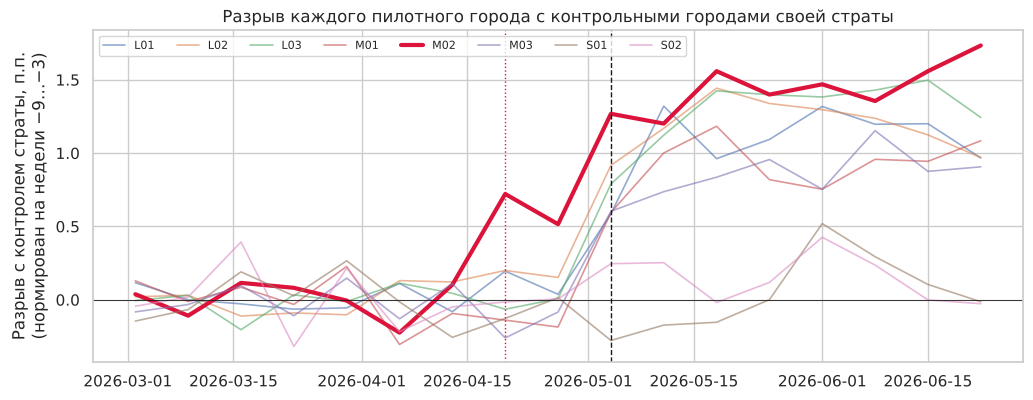

In [8]:
# (1) Разный линейный тренд до запуска: conv ~ FE + treated × t
pt = smf.ols("conv_pp ~ treated:t + " + FE_MAIN, data=pre).fit(
    cov_type="cluster", cov_kwds={"groups": pre["city"]})
print(f"(1) Разница трендов treated − control до запуска: {pt.params['treated:t'] * 7:+.4f} п.п. в неделю, "
      f"p = {pt.pvalues['treated:t']:.3f}")

# (2) Плацебо-DiD по каждому городу: разрыв «город − среднее остальных контрольных городов его страты»
#     в последние 2 недели до запуска против недель −9…−3. Ошибки Ньюи–Уэста (HAC, 7 лагов).
#     Ту же статистику считаем и для контрольных городов: они дают эмпирическое распределение
#     «нормальных» колебаний, с которым сравниваем пилотные города.
rows = []
for city in city_info.index:
    s = city_info.loc[city, "stratum"]
    peers = city_info[(city_info.stratum == s) & (city_info.treated == 0) & (city_info.index != city)].index
    own = pre[pre.city == city].set_index("date")["conv_pp"]
    ref = pre[pre.city.isin(peers)].groupby("date")["conv_pp"].mean()
    g = (own - ref).dropna().to_frame("gap")
    g["late_pre"] = (g.index >= LAUNCH - pd.Timedelta(days=14)).astype(int)
    m = smf.ols("gap ~ late_pre", data=g).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    rows.append({"город": city, "страта": s, "пилотный": int(city_info.loc[city, "treated"]),
                 "плацебо-эффект, п.п.": m.params["late_pre"], "p": m.pvalues["late_pre"]})
placebo_city = pd.DataFrame(rows).set_index("город")
placebo_city["p Holm (8 пилотных)"] = np.nan
is_tr = placebo_city["пилотный"] == 1
placebo_city.loc[is_tr, "p Holm (8 пилотных)"] = multipletests(placebo_city.loc[is_tr, "p"], method="holm")[1]
# Эмпирический p-value: доля контрольных городов с плацебо-эффектом по модулю не меньше, чем у города
null_abs = placebo_city.loc[~is_tr, "плацебо-эффект, п.п."].abs().values
placebo_city["эмпирический p"] = placebo_city["плацебо-эффект, п.п."].abs().apply(
    lambda v: (1 + np.sum(null_abs >= v)) / (1 + len(null_abs)))
print("\n(2) Плацебо-DiD по городам (недели −2…−1 против −9…−3):")
print(placebo_city.sort_values("плацебо-эффект, п.п.", ascending=False))
print(f"Максимальный |эффект| среди контрольных городов: {null_abs.max():.3f} п.п.")

# График разрыва «пилотный город − среднее контрольных городов своей страты»
ctrl_mean = df[df.treated == 0].groupby(["stratum", "week"])["conv_pp"].mean()
gap = (df[df.treated == 1].groupby(["city", "stratum", "week"])["conv_pp"].mean().reset_index())
gap["gap"] = gap["conv_pp"] - ctrl_mean.loc[list(zip(gap["stratum"], gap["week"]))].values
gap["gap"] -= gap.groupby("city")["gap"].transform(lambda s: s[gap.loc[s.index, "week"] < LAUNCH - pd.Timedelta(days=14)].mean())
fig, ax = plt.subplots(figsize=(12, 4.3))
for city, g in gap.groupby("city"):  # разрыв нормирован на средний за недели −9…−3
    bold = city == "M02"
    ax.plot(g["week"], g["gap"], lw=3 if bold else 1.2, alpha=1 if bold else 0.6,
            color="crimson" if bold else None, label=city)
ax.axvline(LAUNCH, color="k", ls="--", lw=1)
ax.axvline(LAUNCH - pd.Timedelta(days=14), color="crimson", ls=":", lw=1)
ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("Разрыв с контролем страты, п.п.\n(нормирован на недели −9…−3)")
ax.set_title("Разрыв каждого пилотного города с контрольными городами своей страты")
ax.legend(ncol=8, fontsize=8, loc="upper left")
show(fig, "04_city_gaps")

* **Общий тест не видит проблем:** разница линейных трендов пилотных и контрольных городов до запуска
  +0.004 п.п. в неделю (p = 0.78).
* **Проверка по городам находит нарушение:** у пилотного города **M02 конверсия выросла на 0.62 п.п. за две недели
  до запуска**. Это самый большой плацебо-эффект среди всех 20 городов, в 2 раза больше максимума среди
  контрольных (0.30 п.п.). На графике разрыв M02 «ступенькой» поднимается около 20 апреля, когда алгоритма ещё нет,
  а после 4 мая растёт ещё раз вместе с остальными пилотными городами. Похоже на локальную маркетинговую акцию,
  которая стартовала раньше алгоритма и продолжается после. Этот факт стоит подтвердить у маркетинга.
* Про p-value в таблице: HAC-ошибки на 63 днях занижены. Например, контрольный город L05 с эффектом −0.17 п.п.
  получает p < 0.001, хотя алгоритма там нет. Поэтому опираемся на эмпирическое распределение по
  контрольным городам. У M02 эмпирический p = 1/13 = 0.077, это минимально возможное значение при 12 контрольных
  городах: ни один контрольный город не дал такого скачка.
* **Вывод:** для M02 предпосылка параллельных трендов нарушена, его рост после запуска нельзя приписать алгоритму.
  В основной спецификации **исключаем M02**, оценку на всех городах показываем как проверку чувствительности.
  Остальные 7 пилотных городов до запуска идут параллельно с контролем.
* Важный урок: агрегированные тесты (линейный тренд, event study на всех городах ниже, плацебо-даты)
  нарушение у одного города из восьми **не ловят**, нужен анализ на уровне отдельных городов.

In [9]:
# (3) Плацебо с ложной датой запуска: берём только пред-период и «запускаем» на 4 недели раньше
def placebo_date(data, fake_launch):
    d = data[data["post"] == 0].copy()
    d["fake_tp"] = d["treated"] * (d["date"] >= fake_launch).astype(int)
    m = smf.ols("conv_pp ~ fake_tp + " + FE_MAIN, data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d["city"]})
    return m.params["fake_tp"], m.pvalues["fake_tp"]


for fake in ["2026-04-06", "2026-04-13", "2026-04-20"]:
    est_all, p_all = placebo_date(df, pd.Timestamp(fake))
    est_cl, p_cl = placebo_date(df[df.city != "M02"], pd.Timestamp(fake))
    print(f"Ложный запуск {fake}: все города {est_all:+.3f} п.п. (p = {p_all:.3f}); "
          f"без M02 {est_cl:+.3f} п.п. (p = {p_cl:.3f})")

Ложный запуск 2026-04-06: все города -0.021 п.п. (p = 0.782); без M02 -0.065 п.п. (p = 0.292)
Ложный запуск 2026-04-13: все города +0.024 п.п. (p = 0.777); без M02 -0.041 п.п. (p = 0.465)
Ложный запуск 2026-04-20: все города +0.050 п.п. (p = 0.620); без M02 -0.036 п.п. (p = 0.488)


Плацебо-тест с ложными датами запуска (6, 13 и 20 апреля) внутри пред-периода «эффекта» не находит:
все оценки по модулю < 0.07 п.п., все p > 0.29, как без M02, так и на всех городах.
На всех городах ложный эффект чуть растёт по мере приближения ложной даты к 20 апреля (−0.02 → +0.05 п.п.),
это след акции M02, но на фоне 8 пилотных городов он теряется.

## 2. Выбор метода причинного вывода

| Метод | Что нужно | Есть ли это в наших данных | Вывод |
|---|---|---|---|
| **A/B-тест (рандомизация пользователей)** | независимость пользователей (SUTVA) | Нет: курьеры общие на город, алгоритм для части заказов меняет загрузку курьеров и ETA у всех | Невозможен / смещён |
| **DiD** | панель до/после, есть необработанные единицы, параллельные тренды | Да: 20 городов × 119 дней, 12 контрольных городов, 9 недель до запуска; параллельность проверена в 1.5 | **Выбран** |
| **RDD** | переменная назначения с порогом | Порога нет: города выбирались бизнесом. Можно было бы взять время как running variable (RDiT), но сильная недельная сезонность, праздники 9–11 мая и «разгон» эффекта делают сравнение «день до / день после» ненадёжным | Не подходит |
| **PSM** | много единиц, отбор по наблюдаемым признакам | Единиц обработки всего 20 городов, сопоставлять почти нечего; пользователей сопоставлять бессмысленно — обработка на уровне города | Не подходит (идея использована как сравнение внутри страт) |
| **IV** | инструмент, который влияет на внедрение и не влияет на конверсию напрямую | Такого инструмента нет | Не подходит |
| **Synthetic control** | одна/несколько обработанных единиц, длинный пред-период | Да, есть | Используем как проверку (раздел 6) |

**Почему DiD.** Внедрение произошло в известный день в части городов, у нас есть длинный пред-период и контрольные
города той же страты. DiD убирает постоянные различия между городами (фиксированные эффекты города) и общие для всех
городов шоки (фиксированные эффекты дня). Неслучайный отбор пилотных городов не мешает, пока он связан с
**уровнем** метрики, а не с её **динамикой** — это и проверено в разделе 1.5.
Особенности, которые учитываем в спецификации:
* праздники бьют по стратам по-разному → эффекты «страта × дата»;
* дни внутри города зависимы (автокорреляция) → кластеризация ошибок по городу (Bertrand, Duflo, Mullainathan, 2004);
* кластеров мало (19–20) → дополнительно wild cluster bootstrap и randomization inference;
* у M02 нарушены параллельные тренды → исключаем из основной оценки.

**Альтернативный дизайн, если бы можно было планировать эксперимент заранее:**
* **Switchback-тест:** в каждом городе алгоритм включается и выключается по случайному расписанию
  (например, блоками по 2–3 часа или по дням). Каждый город сам себе контроль, сезонность и праздники
  балансируются случайностью, а SUTVA выполняется внутри временного блока. Минус — перенос эффекта между блоками
  (курьеры, назначенные старым алгоритмом, ещё в пути), нужен «буфер» между блоками.
* **Рандомизированный гео-эксперимент:** города разбиваются на пары похожих (внутри страты) и в каждой паре
  пилотный город выбирается подбрасыванием монетки. Тогда отбор городов не был бы связан с их размером
  и параллельность трендов была бы ожидаемой по построению.

Обычный A/B по пользователям здесь невозможен: если половина заказов распределяется новым алгоритмом,
а половина старым, они конкурируют за одних и тех же курьеров, и разница между группами не равна эффекту полного
внедрения.

## 3. Оценка эффекта

### 3.1 Основная модель

$$conv_{ct} = \beta \cdot (Treated_c \times Post_t) + \alpha_c + \gamma_{s(c),t} + \varepsilon_{ct}$$

* $\alpha_c$ — фиксированный эффект города (постоянные различия уровней);
* $\gamma_{s,t}$ — фиксированный эффект «страта × дата» (сезонность, праздники и тренды, свои для каждой страты);
* $\beta$ — эффект алгоритма в п.п. конверсии (ATT — средний эффект на пилотных городах);
* ошибки кластеризованы по городу, ДИ по t-распределению с G − 1 степенями свободы.

Основная выборка — без M02 (см. 1.5).

In [10]:
def did(data, y="conv_pp", fe=None, extra="", weights=None, treat="tp"):
    """DiD с фиксированными эффектами; кластеризованные по городу ошибки, ДИ по t(G-1)."""
    fe = FE_MAIN if fe is None else fe
    formula = f"{y} ~ {treat} + {fe}" + (f" + {extra}" if extra else "")
    if weights is None:
        m = smf.ols(formula, data=data)
    else:
        m = smf.wls(formula, data=data, weights=data[weights])
    rank = np.linalg.matrix_rank(m.exog)
    assert rank == m.exog.shape[1], f"матрица неполного ранга: {rank} < {m.exog.shape[1]}"
    groups = data["city"].astype("category").cat.codes
    res = m.fit(cov_type="cluster", cov_kwds={"groups": groups})
    G = data["city"].nunique()
    est, se = res.params[treat], res.bse[treat]
    q = stats.t.ppf(1 - ALPHA / 2, G - 1)
    p = 2 * stats.t.sf(abs(est / se), G - 1)
    return {"est": est, "se": se, "ci_low": est - q * se, "ci_high": est + q * se, "p": p,
            "n_obs": int(res.nobs), "n_cities": G, "model": res}


main_df = df[df["city"] != "M02"].copy()
main = did(main_df)
base_conv = main_df.loc[(main_df.treated == 1) & (main_df.post == 0), "conv_pp"].mean()
print(f"Основная оценка (без M02): β = {main['est']:+.3f} п.п., SE = {main['se']:.3f}, "
      f"95% ДИ [{main['ci_low']:+.3f}; {main['ci_high']:+.3f}], p = {main['p']:.2g}")
print(f"Относительно базовой конверсии пилотных городов ({base_conv:.2f}%): "
      f"{main['est'] / base_conv:+.1%} [{main['ci_low'] / base_conv:+.1%}; {main['ci_high'] / base_conv:+.1%}]")
print(f"Наблюдений: {main['n_obs']}, городов: {main['n_cities']}")

Основная оценка (без M02): β = +0.729 п.п., SE = 0.153, 95% ДИ [+0.408; +1.050], p = 0.00015
Относительно базовой конверсии пилотных городов (11.83%): +6.2% [+3.5%; +8.9%]
Наблюдений: 2255, городов: 19


**Дополнительные способы получить p-value при малом числе кластеров.**
Кластеризованные ошибки при 19 городах могут быть занижены. Поэтому:
1. **Wild cluster bootstrap** (Cameron, Gelbach, Miller, 2008): веса Webb, нулевая гипотеза β = 0 наложена.
2. **Randomization inference:** перебираем *все* способы выбрать пилотные города с тем же числом внутри каждой
   страты (3 из 6 крупных, 2 из 6 средних, 2 из 7 малых = 20 · 15 · 21 = 6 300 вариантов) и смотрим,
   насколько реальная оценка выделяется среди «плацебо-оценок». Этот тест не опирается на асимптотику.

Для скорости оба метода используют теорему Фриша–Во–Ловелла: фиксированные эффекты один раз «вычищаются»
из y и из индикатора внедрения, после чего β считается как простая регрессия остатков.

β = +0.729 п.п. (совпадает со statsmodels: +0.729)
p-value: кластеризованные SE 0.00015; wild cluster bootstrap (B = 1999) 0.0000; randomization inference (6300 перестановок) 0.0008
Ранг реальной оценки среди перестановок: 5 из 6300


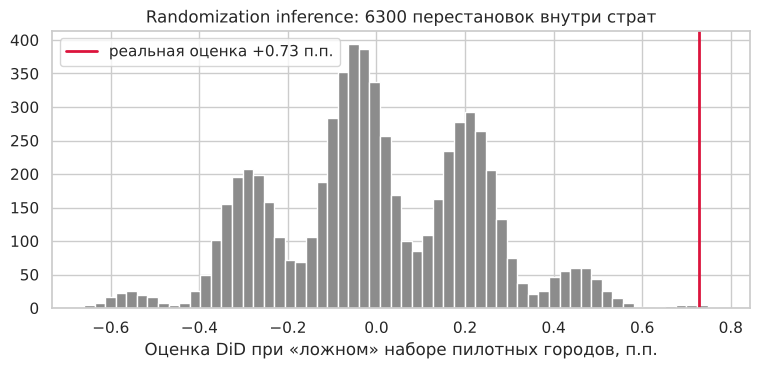

In [11]:
def fe_residualizer(data, fe=FE_MAIN):
    """Возвращает функцию M(v) = v − Z(Z⁺v): остатки от регрессии на фиксированные эффекты."""
    Z = np.asarray(patsy.dmatrix(fe, data, return_type="dataframe"))
    Z_pinv = np.linalg.pinv(Z)
    return lambda v: v - Z @ (Z_pinv @ v)


def cluster_t(d_res, y_res, groups, n_params):
    """β и t-статистика с кластеризованной ошибкой для регрессии остатков y_res на d_res."""
    beta = d_res @ y_res / (d_res @ d_res)
    u = y_res - beta * d_res
    scores = pd.Series(d_res * u).groupby(groups).sum().values
    G, N = len(scores), len(u)
    c = G / (G - 1) * (N - 1) / (N - n_params)
    se = np.sqrt(c * (scores ** 2).sum()) / (d_res @ d_res)
    return beta, beta / se


M = fe_residualizer(main_df)
n_par = np.linalg.matrix_rank(np.asarray(patsy.dmatrix(FE_MAIN, main_df))) + 1
y_res = M(main_df["conv_pp"].values)
d_res = M(main_df["tp"].values.astype(float))
groups = main_df["city"].values
beta_hat, t_hat = cluster_t(d_res, y_res, groups, n_par)

# 1) Wild cluster bootstrap (restricted: при H0 остатки = y_res)
B = 1999
cities_arr = np.unique(groups)
city_idx = pd.Series(np.arange(len(cities_arr)), index=cities_arr)[groups].values
webb = np.array([-np.sqrt(1.5), -1, -np.sqrt(0.5), np.sqrt(0.5), 1, np.sqrt(1.5)])
t_boot = np.empty(B)
for b in range(B):
    w = rng.choice(webb, size=len(cities_arr))[city_idx]
    y_star = M(w * y_res)
    t_boot[b] = cluster_t(d_res, y_star, groups, n_par)[1]
p_wild = np.mean(np.abs(t_boot) >= abs(t_hat))

# 2) Randomization inference: все перестановки пилотных городов внутри страт
pools = {s: list(city_info[(city_info.stratum == s) & (city_info.index != "M02")].index) for s in STRATA}
n_tr = {s: int(city_info.loc[pools[s], "treated"].sum()) for s in STRATA}
post_arr = main_df["post"].values
ri_est = []
for combo in product(*[combinations(pools[s], n_tr[s]) for s in STRATA]):
    fake_treated = np.isin(groups, sum(map(list, combo), []))
    dr = M((fake_treated * post_arr).astype(float))
    ri_est.append(dr @ y_res / (dr @ dr))
ri_est = np.array(ri_est)
p_ri = np.mean(np.abs(ri_est) >= abs(beta_hat) - 1e-12)

print(f"β = {beta_hat:+.3f} п.п. (совпадает со statsmodels: {main['est']:+.3f})")
print(f"p-value: кластеризованные SE {main['p']:.2g}; wild cluster bootstrap (B = {B}) {p_wild:.4f}; "
      f"randomization inference ({len(ri_est)} перестановок) {p_ri:.4f}")
print(f"Ранг реальной оценки среди перестановок: {np.sum(ri_est >= beta_hat - 1e-12)} из {len(ri_est)}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(ri_est, bins=60, color="#8C8C8C")
ax.axvline(beta_hat, color="crimson", lw=2, label=f"реальная оценка {beta_hat:+.2f} п.п.")
ax.set_xlabel("Оценка DiD при «ложном» наборе пилотных городов, п.п.")
ax.set_title(f"Randomization inference: {len(ri_est)} перестановок внутри страт")
ax.legend()
show(fig, "05_randomization_inference")

### 3.2 Event study: динамика эффекта и проверка пред-трендов
Вместо одного $\beta$ оцениваем отдельный коэффициент для каждой недели относительно запуска
(опорная неделя −1). Коэффициенты до запуска — проверка параллельных трендов, после запуска — динамика эффекта.

Совместный тест «все коэффициенты до запуска = 0»: без M02 F = 0.65, p = 0.728; все города F = 0.87, p = 0.558
rel_week      -9      -8      -7      -6      -5      -4      -3      -2     -1     0      1      2      3      4      5      6      7 
est       0.0066  0.0078  0.1018 -0.0488  0.1349 -0.0494 -0.0115 -0.0319 0.0000 0.4665 0.7246 0.7519 0.7624 0.8786 0.8879 0.7660 0.6933
lo       -0.1689 -0.1181 -0.1014 -0.2338 -0.0682 -0.2183 -0.1588 -0.2169 0.0000 0.1555 0.3124 0.2928 0.3960 0.5871 0.5416 0.3680 0.2997
hi        0.1821  0.1338  0.3050  0.1361  0.3379  0.1196  0.1358  0.1531 0.0000 0.7775 1.1368 1.2110 1.1288 1.1701 1.2341 1.1639 1.0870


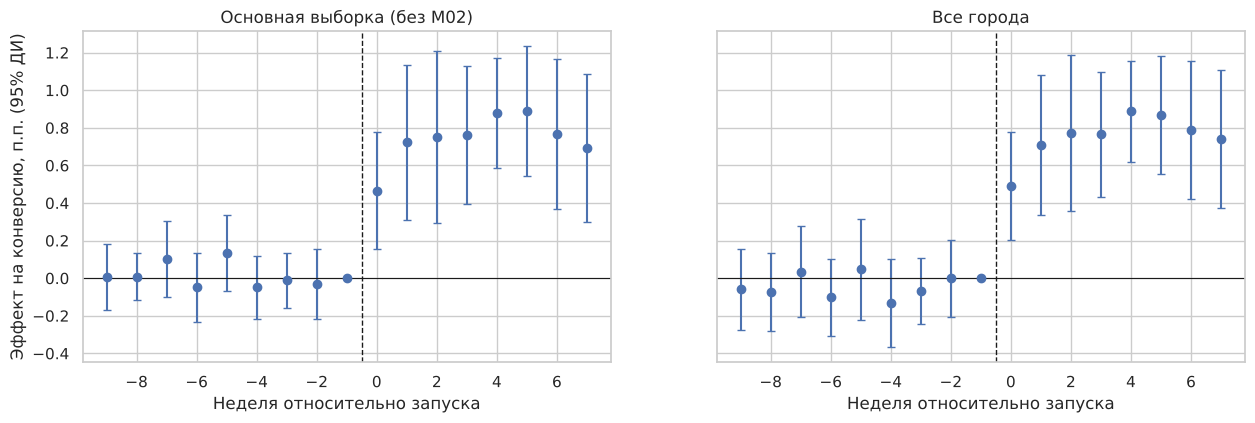

In [12]:
def event_study(data, ref=-1):
    d = data.copy()
    weeks = sorted(d["rel_week"].unique())
    names = []
    for k in weeks:
        if k == ref:
            continue
        nm = f"ev_{'m' if k < 0 else 'p'}{abs(k)}"
        d[nm] = ((d["rel_week"] == k) & (d["treated"] == 1)).astype(int)
        names.append((k, nm))
    res = smf.ols("conv_pp ~ " + " + ".join(n for _, n in names) + " + " + FE_MAIN, data=d).fit(
        cov_type="cluster", cov_kwds={"groups": d["city"].astype("category").cat.codes})
    G = d["city"].nunique()
    q = stats.t.ppf(0.975, G - 1)
    out = pd.DataFrame([{"rel_week": k, "est": res.params[n], "se": res.bse[n]} for k, n in names])
    out = pd.concat([out, pd.DataFrame([{"rel_week": ref, "est": 0.0, "se": 0.0}])]).sort_values("rel_week")
    out["lo"], out["hi"] = out["est"] - q * out["se"], out["est"] + q * out["se"]
    leads = [n for k, n in names if k < ref]
    wald = res.wald_test(" , ".join(f"{n} = 0" for n in leads), use_f=True, scalar=True)
    return out, wald


es_main, wald_main = event_study(main_df)
es_all, wald_all = event_study(df)
print(f"Совместный тест «все коэффициенты до запуска = 0»: без M02 F = {wald_main.statistic:.2f}, "
      f"p = {wald_main.pvalue:.3f}; все города F = {wald_all.statistic:.2f}, p = {wald_all.pvalue:.3f}")
print(es_main.set_index("rel_week")[["est", "lo", "hi"]].T)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3), sharey=True)
for ax, (es, title) in zip(axes, [(es_main, "Основная выборка (без M02)"), (es_all, "Все города")]):
    ax.errorbar(es["rel_week"], es["est"], yerr=[es["est"] - es["lo"], es["hi"] - es["est"]],
                fmt="o", capsize=3, color="#4C72B0")
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(-0.5, color="k", ls="--", lw=1)
    ax.set_xlabel("Неделя относительно запуска")
    ax.set_title(title)
axes[0].set_ylabel("Эффект на конверсию, п.п. (95% ДИ)")
show(fig, "06_event_study")

* **Без M02** все 8 коэффициентов до запуска лежат в пределах ±0.14 п.п., их ДИ накрывают ноль, совместный F-тест
  не отвергает параллельность трендов (F = 0.65, p = 0.73).
* После запуска эффект появляется сразу: в неделю 0 он +0.47 п.п. (алгоритм «разгоняется»), с недели 1 выходит
  на уровень +0.7…+0.9 п.п. и не затухает до конца наблюдения. Значит, это не кратковременный эффект новизны.
* На всех городах картина почти та же (F-тест p = 0.56): как и говорилось выше, общий тест скачок M02 не видит.

### 3.3 Чувствительность к спецификации
Проверяем, насколько оценка зависит от выборки, окна, фиксированных эффектов, трендов, весов и агрегации.

                                                      est  ci_low  ci_high      p     n_obs  n_cities
1. Основная: город + страта×дата, без M02          0.7291  0.4082   1.0499 0.0002 2255.0000   19.0000
2. Все города (с M02)                              0.7922  0.4692   1.1151 0.0001 2374.0000   20.0000
3. Город + дата (без учёта страт), без M02         0.7801  0.4129   1.1474 0.0003 2255.0000   19.0000
4. + линейные тренды городов                       0.6548  0.3236   0.9859 0.0006 2255.0000   19.0000
5. Веса = DAU (эффект на пользователя)             1.0593  0.8848   1.2337 0.0000 2255.0000   19.0000
6. Без праздничных дней                            0.7334  0.4158   1.0510 0.0001 2141.0000   19.0000
7. Без недели разгона (1-я неделя после запуска)   0.7683  0.4360   1.1006 0.0001 2122.0000   19.0000
8. Окно ±4 недели                                  0.6994  0.3730   1.0259 0.0003 1063.0000   19.0000
9. Окно ±6 недель                                  0.7461  0.4390   1.0532 0.0001 

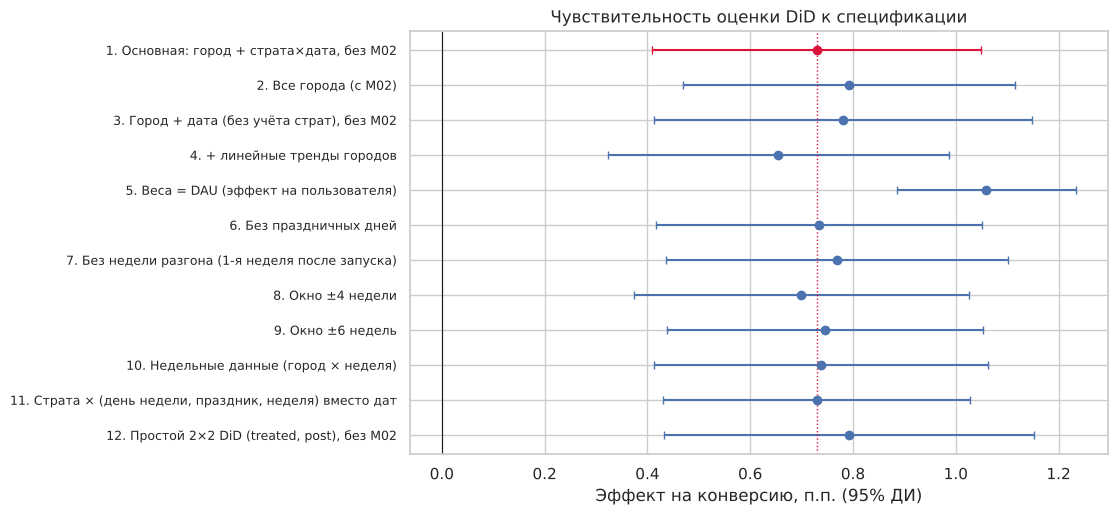

In [13]:
specs = {}
specs["1. Основная: город + страта×дата, без M02"] = main
specs["2. Все города (с M02)"] = did(df)
specs["3. Город + дата (без учёта страт), без M02"] = did(main_df, fe="C(city) + C(date)")
# Линейные тренды городов: для опорного города страты тренд не заводим (он входит в «страта × дата»)
trend_cols = []
for c in main_df.loc[main_df["city_fe"] != "_ref", "city"].unique():
    main_df[f"trend_{c}"] = main_df["t"] * (main_df["city"] == c)
    trend_cols.append(f"trend_{c}")
specs["4. + линейные тренды городов"] = did(main_df, extra=" + ".join(trend_cols))
specs["5. Веса = DAU (эффект на пользователя)"] = did(main_df, weights="active_users")
specs["6. Без праздничных дней"] = did(main_df[main_df.holiday == 0])
specs["7. Без недели разгона (1-я неделя после запуска)"] = did(main_df[main_df.rel_week != 0])
specs["8. Окно ±4 недели"] = did(main_df[main_df.rel_week.between(-4, 3)])
specs["9. Окно ±6 недель"] = did(main_df[main_df.rel_week.between(-6, 5)])
# Недельная агрегация убирает автокорреляцию внутри недели
wk = (main_df.groupby(["city", "week", "stratum", "stratum_week"], as_index=False)
      .agg(orders=("orders", "sum"), active_users=("active_users", "sum"), tp=("tp", "max")))
wk["conv_pp"] = 100 * wk["orders"] / wk["active_users"]
wk["city_fe"] = np.where(wk["city"].isin(REF_CITIES), "_ref", wk["city"])
specs["10. Недельные данные (город × неделя)"] = did(wk, fe="C(city_fe, Treatment('_ref')) + C(stratum_week)")
# Относительный эффект: метрика, делённая на среднюю конверсию города до запуска
main_df["conv_rel"] = 100 * main_df["conv_pp"] / main_df.groupby("city")["conv_pp"].transform(
    lambda s: s[main_df.loc[s.index, "post"] == 0].mean())
rel = did(main_df, y="conv_rel")
specs["11. Страта × (день недели, праздник, неделя) вместо дат"] = did(
    main_df, fe="C(city_fe, Treatment('_ref')) + C(stratum):C(weekday) + C(stratum):holiday + C(stratum):C(week)")
# Классический 2×2 DiD средних (без FE), для сравнения
specs["12. Простой 2×2 DiD (treated, post), без M02"] = did(main_df, fe="treated + post")

sens = pd.DataFrame({k: {c: v[c] for c in ["est", "ci_low", "ci_high", "p", "n_obs", "n_cities"]}
                     for k, v in specs.items()}).T
print(sens)
print(f"\nОтносительный эффект (спецификация 1 на метрике «% от уровня города до запуска»): "
      f"{rel['est']:+.2f}% [{rel['ci_low']:+.2f}; {rel['ci_high']:+.2f}], p = {rel['p']:.2g}")

fig, ax = plt.subplots(figsize=(9, 5.5))
ypos = np.arange(len(sens))[::-1]
colors = ["crimson" if i == 0 else "#4C72B0" for i in range(len(sens))]
for yp, (_, r), c in zip(ypos, sens.iterrows(), colors):
    ax.errorbar(r["est"], yp, xerr=[[r["est"] - r["ci_low"]], [r["ci_high"] - r["est"]]], fmt="o", color=c, capsize=3)
ax.axvline(0, color="k", lw=0.8)
ax.axvline(main["est"], color="crimson", ls=":", lw=1)
ax.set_yticks(ypos, sens.index, fontsize=9)
ax.set_xlabel("Эффект на конверсию, п.п. (95% ДИ)")
ax.set_title("Чувствительность оценки DiD к спецификации")
show(fig, "07_sensitivity")

**Основной результат и робастность:**
* Основная оценка: **+0.73 п.п. к конверсии [95% ДИ +0.41; +1.05], p = 0.00015**, это **+6.2% [+3.5%; +8.9%]**
  к базовой конверсии пилотных городов (11.8%).
* Значимость не держится на асимптотике кластеризованных ошибок: wild cluster bootstrap — ни одна из 1 999 выборок
  не дала |t| больше реального (p < 0.001); randomization inference — реальная оценка 5-я по величине среди
  6 300 возможных наборов пилотных городов (p = 0.0008).
* Все 12 спецификаций дают оценки от +0.65 до +1.06 п.п., все значимы, все ДИ не включают ноль:
  * окна ±4 и ±6 недель, недельная агрегация, исключение праздников и недели разгона почти не меняют оценку (0.70–0.77);
  * линейные тренды городов дают самую низкую оценку (+0.65), но ДИ сильно пересекается с основным:
    поправка на тренды мало что меняет, что согласуется с отсутствием пред-трендов;
  * без учёта страт (город + дата) оценка +0.78: в наших данных праздничное смещение небольшое;
  * с M02 оценка +0.79, то есть акция в M02 завышает эффект на +0.06 п.п.;
  * взвешивание по DAU даёт +1.06: это эффект на «среднего пользователя», а не на «средний город».
    Большая часть пользователей живёт в крупных городах, где эффект больше (см. 3.4).

### 3.4 Эффект по стратам (гетерогенность)
Решение нужно принимать по каждой страте городов, поэтому оцениваем эффект отдельно для крупных, средних и малых
городов. Три проверки — поправка Холма.

In [14]:
def did_by_stratum(data, y, **kw):
    rows = []
    for s in STRATA:
        r = did(data[data.stratum == s], y=y, fe="C(city) + C(date)", **kw)
        rows.append({"страта": s, "est": r["est"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                     "p": r["p"], "пилотных": int(data[data.stratum == s].groupby("city")["treated"].first().sum()),
                     "контрольных": int((1 - data[data.stratum == s].groupby("city")["treated"].first()).sum())})
    out = pd.DataFrame(rows).set_index("страта")
    out["p Holm"] = multipletests(out["p"], method="holm")[1]
    return out


het = did_by_stratum(main_df, "conv_pp")
print("Эффект на конверсию по стратам, п.п.:")
print(het)

# Формальная проверка различий: взаимодействие tp × страта
het_m = smf.ols("conv_pp ~ tp:C(stratum) + " + FE_MAIN, data=main_df).fit(
    cov_type="cluster", cov_kwds={"groups": main_df["city"].astype("category").cat.codes})
names = [n for n in het_m.params.index if n.startswith("tp:")]
w = het_m.wald_test(f"{names[0]} = {names[2]}, {names[1]} = {names[2]}", use_f=True, scalar=True)
print(f"\nТест «эффект одинаков во всех стратах»: F = {w.statistic:.2f}, p = {w.pvalue:.3g}")

Эффект на конверсию по стратам, п.п.:
          est  ci_low  ci_high      p  пилотных  контрольных  p Holm
страта                                                              
large  1.1617  0.9491   1.3743 0.0000         3            3  0.0001
medium 0.9219  0.7523   1.0915 0.0000         2            4  0.0001
small  0.0939 -0.1026   0.2903 0.2865         2            5  0.2865



Тест «эффект одинаков во всех стратах»: F = 54.35, p = 2.36e-08


**Эффект сильно разный по стратам** (тест равенства эффектов F = 54, p < 0.001):

| Страта | Эффект, п.п. | 95% ДИ | p (Холм) |
|---|---|---|---|
| large | +1.16 | [+0.95; +1.37] | < 0.001 |
| medium | +0.92 | [+0.75; +1.09] | < 0.001 |
| small | +0.09 | [−0.10; +0.29] | 0.29 |

В малых городах эффекта нет: ДИ позволяет исключить рост больше ≈ 0.3 п.п.
Логично с точки зрения продукта: в малых городах мало курьеров, короткий ETA там обещать нечем.
Оценки по стратам опираются на 2–3 пилотных города в страте, поэтому их стоит воспринимать как ориентир,
но разница между крупными/средними и малыми городами очень большая и сомнений не вызывает.

## 4. Guardrail-анализ

Новый алгоритм обещает более короткий ETA. Риск — курьеры не будут успевать: вырастут опоздания, время
доставки и отмены. Также проверяем, не упало ли число активных пользователей.

Для каждого guardrail **заранее задаём допустимый порог ухудшения** (non-inferiority margin) и проверяем
односторонний 95% ДИ: guardrail «в норме», если верхняя граница ухудшения ниже порога.

| Guardrail | Плохое направление | Допустимый порог |
|---|---|---|
| Доля опозданий | рост | +1.0 п.п. |
| Доля отмен | рост | +0.3 п.п. |
| Время доставки | рост | +2 мин |
| DAU | падение | −2% |

Поправка на множественные проверки: Холм по 4 guardrail-метрикам (и отдельно по стратам).

Guardrail, все пилотные города (без M02):
                         est  ci_low  ci_high  p (ухудшение)  граница 1-ст. ДИ   порог  в пределах порога  p Holm
метрика                                                                                                          
Доля опозданий, п.п.  1.2943  0.3906   2.1980         0.0038            2.0402  1.0000              False  0.0151
Доля отмен, п.п.      0.3393  0.0342   0.6443         0.0156            0.5910  0.3000              False  0.0468
Время доставки, мин   1.2692  0.0565   2.4820         0.0206            2.2702  2.0000              False  0.0468
DAU, лог (≈ доля)    -0.0015 -0.0072   0.0042         0.2912           -0.0062 -0.0200               True  0.2912



Guardrail по стратам (Холм по 12 проверкам):
                                est  ci_low  ci_high  p (ухудшение)  граница 1-ст. ДИ   порог  в пределах порога  p Holm
страта метрика                                                                                                          
large  Доля опозданий, п.п.  0.1790  0.1068   0.2511         0.0007            0.2355  1.0000               True  0.0063
       Доля отмен, п.п.      0.0343 -0.0238   0.0924         0.0949            0.0799  0.3000               True  0.4155
       Время доставки, мин  -0.3914 -0.6436  -0.1392         0.9948           -0.1937  2.0000               True  1.0000
       DAU, лог (≈ доля)     0.0056 -0.0044   0.0157         0.8950           -0.0023 -0.0200               True  1.0000
medium Доля опозданий, п.п.  0.5433  0.4080   0.6787         0.0001            0.6494  1.0000               True  0.0007
       Доля отмен, п.п.      0.0977  0.0506   0.1448         0.0016            0.1346  0.3000              

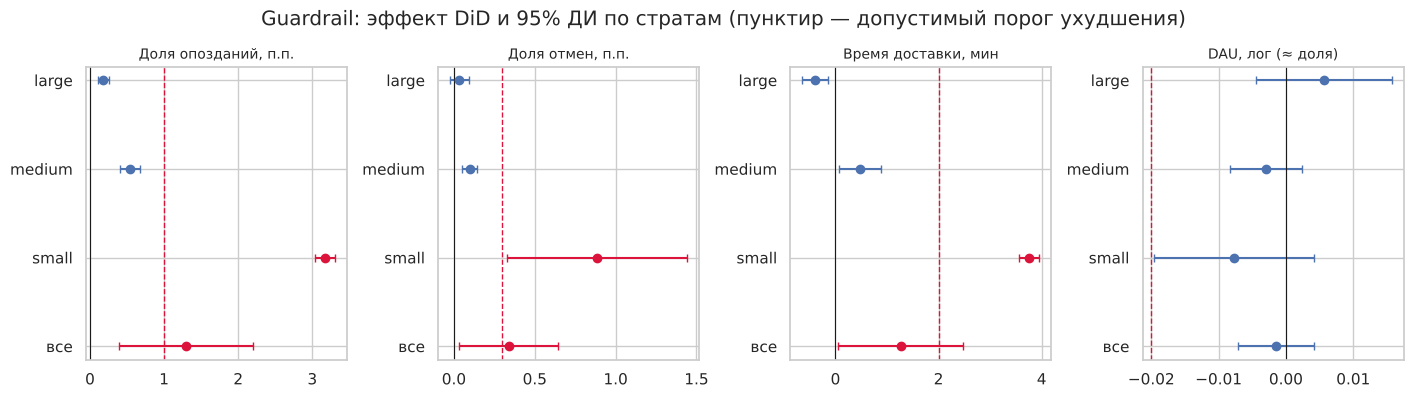

In [15]:
GUARDRAILS = {  # метрика: (название, знак ухудшения, порог)
    "late_pp": ("Доля опозданий, п.п.", +1, 1.0),
    "cancel_pp": ("Доля отмен, п.п.", +1, 0.3),
    "avg_delivery_min": ("Время доставки, мин", +1, 2.0),
    "log_dau": ("DAU, лог (≈ доля)", -1, 0.02),
}


def guardrail_row(data, y, fe=None):
    name, sign, margin = GUARDRAILS[y]
    r = did(data, y=y, fe=fe)
    G = data["city"].nunique()
    # односторонний p-value для гипотезы «стало хуже»
    p_worse = stats.t.sf(sign * r["est"] / r["se"], G - 1)
    # граница одностороннего 95% ДИ в сторону ухудшения
    bound = r["est"] + sign * stats.t.ppf(0.95, G - 1) * r["se"]
    return {"метрика": name, "est": r["est"], "ci_low": r["ci_low"], "ci_high": r["ci_high"],
            "p (ухудшение)": p_worse, "граница 1-ст. ДИ": bound, "порог": sign * margin,
            "в пределах порога": bool(sign * bound < margin)}


g_all = pd.DataFrame([guardrail_row(main_df, y) for y in GUARDRAILS]).set_index("метрика")
g_all["p Holm"] = multipletests(g_all["p (ухудшение)"], method="holm")[1]
print("Guardrail, все пилотные города (без M02):")
print(g_all)

g_str = []
for s in STRATA:
    sub = main_df[main_df.stratum == s]
    for y in GUARDRAILS:
        row = guardrail_row(sub, y, fe="C(city) + C(date)")
        row["страта"] = s
        g_str.append(row)
g_str = pd.DataFrame(g_str).set_index(["страта", "метрика"])
g_str["p Holm"] = multipletests(g_str["p (ухудшение)"], method="holm")[1]
print("\nGuardrail по стратам (Холм по 12 проверкам):")
print(g_str)

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (y, (name, sign, margin)) in zip(axes, GUARDRAILS.items()):
    sub = g_str.xs(name, level="метрика").reindex(STRATA)
    allrow = g_all.loc[name]
    est = list(sub["est"]) + [allrow["est"]]
    lo = list(sub["ci_low"]) + [allrow["ci_low"]]
    hi = list(sub["ci_high"]) + [allrow["ci_high"]]
    labels = STRATA + ["все"]
    pos = np.arange(len(labels))[::-1]
    for i in range(len(labels)):
        c = "crimson" if (sign * (hi[i] if sign > 0 else lo[i]) > margin) else "#4C72B0"
        ax.errorbar(est[i], pos[i], xerr=[[est[i] - lo[i]], [hi[i] - est[i]]], fmt="o", color=c, capsize=3)
    ax.axvline(0, color="k", lw=0.8)
    ax.axvline(sign * margin, color="crimson", ls="--", lw=1)
    ax.set_yticks(pos, labels)
    ax.set_title(name, fontsize=10)
fig.subplots_adjust(wspace=0.35)
fig.suptitle("Guardrail: эффект DiD и 95% ДИ по стратам (пунктир — допустимый порог ухудшения)", y=1.03)
show(fig, "08_guardrails")

**Вывод по guardrail:**
* **В целом по пилоту guardrail нарушен:** доля опозданий +1.29 п.п. [+0.39; +2.20] (порог +1 п.п.),
  отмены +0.34 п.п. [+0.03; +0.64] (порог +0.3), время доставки +1.27 мин [+0.06; +2.48] (порог +2 мин).
  Все три ухудшения значимы после поправки Холма (p = 0.015–0.047), и ни для одного нельзя доказать,
  что ухудшение меньше порога. DAU не изменился (−0.15% [−0.7%; +0.4%]).
* **По стратам видно, откуда это берётся:**
  * **малые города:** опоздания +3.17 п.п. (≈ 7.9% → 11.1%, рост в 1.4 раза), отмены +0.89 п.п.,
    время доставки +3.8 мин. Все три метрики значимо хуже и выходят за допустимые пороги;
  * **средние города:** опоздания +0.54 п.п. и отмены +0.10 п.п. значимо выросли, но с запасом в пределах порогов
    (верхние границы 0.65 и 0.13 п.п.), время доставки +0.47 мин — тоже в пределах;
  * **крупные города:** опоздания +0.18 п.п. (значимо, но в 4 раза ниже порога), время доставки даже сократилось
    на 0.4 мин, отмены не изменились.
* Итак, алгоритм обещает короткий ETA везде, но выполнить обещание может только там, где много курьеров.
  В малых городах выигрыша по конверсии нет, а клиенты чаще получают заказ с опозданием.

## 5. Продуктовый вывод: экономика по стратам

Переводим эффекты в деньги на один город в месяц (30 дней). Допущения (их стоит согласовать с финансами):
* маржинальная прибыль с заказа — 12% от среднего чека;
* стоимость опоздавшего заказа — 150 ₽ (промокод-компенсация) + потеря 2% будущей выручки клиента
  за следующий месяц из-за ухудшения опыта, считаем как ещё 100 ₽;
* стоимость отмены — потерянная маржа заказа + 50 ₽ на сборку;
* стоимость сопровождения алгоритма — 150 тыс. ₽ на город в месяц (инфраструктура и поддержка).

In [16]:
MARGIN_RATE, LATE_COST, CANCEL_EXTRA, RUN_COST = 0.12, 250, 50, 150_000

econ = []
for s in STRATA:
    tr_post = main_df[(main_df.stratum == s) & (main_df.treated == 1) & (main_df.post == 1)]
    dau = tr_post["active_users"].mean()
    orders = tr_post["orders"].mean()
    aov = tr_post["aov"].mean()
    eff = het.loc[s]
    late = g_str.loc[(s, "Доля опозданий, п.п.")]
    canc = g_str.loc[(s, "Доля отмен, п.п.")]
    extra_orders = dau * eff["est"] / 100 * 30
    gain = extra_orders * aov * MARGIN_RATE
    late_cost = orders * 30 * late["est"] / 100 * LATE_COST
    canc_cost = orders * 30 * canc["est"] / 100 * (aov * MARGIN_RATE + CANCEL_EXTRA)
    net = gain - late_cost - canc_cost - RUN_COST
    # Пессимистичный сценарий: нижняя граница ДИ эффекта и верхние границы ДИ guardrail
    net_low = (dau * eff["ci_low"] / 100 * 30 * aov * MARGIN_RATE
               - orders * 30 * late["ci_high"] / 100 * LATE_COST
               - orders * 30 * canc["ci_high"] / 100 * (aov * MARGIN_RATE + CANCEL_EXTRA) - RUN_COST)
    econ.append({"страта": s, "DAU": dau, "заказов/день": orders, "доп. заказов/мес": extra_orders,
                 "доп. маржа, тыс ₽": gain / 1e3, "опоздания, тыс ₽": late_cost / 1e3,
                 "отмены, тыс ₽": canc_cost / 1e3, "сопровождение, тыс ₽": RUN_COST / 1e3,
                 "итого, тыс ₽/мес": net / 1e3, "пессимистично, тыс ₽/мес": net_low / 1e3})
econ = pd.DataFrame(econ).set_index("страта")
print(econ.round(1))

              DAU  заказов/день  доп. заказов/мес  доп. маржа, тыс ₽  опоздания, тыс ₽  отмены, тыс ₽  сопровождение, тыс ₽  итого, тыс ₽/мес  пессимистично, тыс ₽/мес
страта                                                                                                                                                                 
large  60198.2000     9112.2000        20979.8000          3653.5000          122.3000        21.0000              150.0000         3360.1000                 2606.7000
medium 20315.2000     2623.6000         5618.4000           877.9000          106.9000        15.9000              150.0000          605.1000                  409.3000
small   5481.1000      564.5000          154.4000            24.1000          134.2000        30.9000              150.0000         -291.0000                 -366.6000


### Рекомендация

| Страта | Конверсия | Guardrail | Экономика, на город в месяц | Решение |
|---|---|---|---|---|
| **large** | +1.16 п.п. (+8–9%) | в норме, время доставки даже лучше | ≈ +3.4 млн ₽ (пессимистично +2.6) | **Внедрять** |
| **medium** | +0.92 п.п. (+8%) | ухудшение значимо, но в пределах порогов | ≈ +0.6 млн ₽ (пессимистично +0.4) | **Внедрять с мониторингом опозданий** |
| **small** | +0.09 п.п., незначимо | нарушен: опоздания +3.2 п.п., отмены, +3.8 мин | ≈ −0.3 млн ₽ | **Откатить и доработать** |

**1. Крупные и средние города — раскатывать на все города страты.** Эффект большой, устойчивый ко всем
спецификациям, не затухает за 8 недель, и даже при пессимистичных допущениях окупает сопровождение
в разы. Guardrail-метрики в этих стратах в пределах допустимого. В средних городах доля опозданий выросла на
0.5 п.п., поэтому на раскатке нужен мониторинг опозданий с автоматическим откатом при превышении порога 1 п.п.

**2. Малые города — откатить на пилотных городах S01, S02 и не раскатывать.** Рост конверсии не доказан
(ДИ позволяет исключить эффект больше 0.3 п.п.), а guardrail нарушен по трём метрикам из трёх операционных.
Даже без учёта долгосрочного оттока из-за опозданий экономика отрицательная.

**3. Модифицировать алгоритм для городов с низкой плотностью курьеров.** Причина ухудшения в том, что ETA обещает
больше, чем может выполнить логистика. Варианты: добавлять к ETA буфер при малом числе свободных курьеров,
либо включать новый ETA только при плотности курьеров выше порога. Модифицированную версию стоит проверить
в малых городах **switchback-тестом** (раздел 2), где каждый город сам себе контроль.

**Оговорки:**
* Город M02 исключён из-за акции: нужно подтвердить у маркетинга, что она была. Если M02 оставить,
  эффект почти не меняется (+0.79 вместо +0.73 п.п.), решение то же.
* Пилотных городов в каждой страте 2–3, поэтому оценки по стратам менее точны, чем общая. Их стоит перепроверить
  после раскатки: оставить 1–2 контрольных города в крупной и средней страте ещё на 4 недели как holdout.
* Денежная модель держится на допущениях о марже и стоимости опоздания. Но вывод по малым городам
  от них не зависит: там нет ни эффекта на конверсию, ни приемлемых guardrail.

## 6. Бонус

### 6.1 Наивные оценки против DiD

                                         est  ci_low  ci_high      p
До/после в пилотных городах           1.3230  1.0475   1.5984 0.0000
Пилотные vs контрольные после запуска 1.0700  0.8152   1.3248 0.0000
Простой 2×2 DiD (все города)          0.7922  0.4692   1.1151 0.0001
DiD основной (без M02, страта × дата) 0.7291  0.4082   1.0499 0.0002

Изменение конверсии в контрольных городах за тот же период: +0.531 п.п.
Разница уровней пилотных и контрольных городов до запуска: +0.278 п.п.


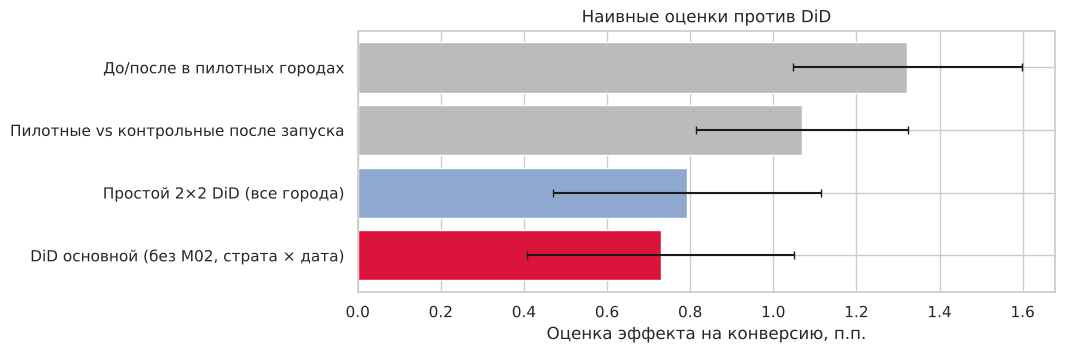

In [17]:
def mean_diff_ci(a, b):
    """Разница средних (Welch) с 95% ДИ; наблюдения — город-дни, без учёта зависимости."""
    diff = a.mean() - b.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    p = stats.ttest_ind(a, b, equal_var=False).pvalue
    return diff, diff - 1.96 * se, diff + 1.96 * se, p


tr, ct = main_df[main_df.treated == 1], main_df[main_df.treated == 0]
naive = {
    "До/после в пилотных городах": mean_diff_ci(tr[tr.post == 1]["conv_pp"], tr[tr.post == 0]["conv_pp"]),
    "Пилотные vs контрольные после запуска": mean_diff_ci(tr[tr.post == 1]["conv_pp"], ct[ct.post == 1]["conv_pp"]),
    "Простой 2×2 DiD (все города)": tuple(specs["2. Все города (с M02)"][k] for k in ["est", "ci_low", "ci_high", "p"]),
    "DiD основной (без M02, страта × дата)": tuple(main[k] for k in ["est", "ci_low", "ci_high", "p"]),
}
naive = pd.DataFrame(naive, index=["est", "ci_low", "ci_high", "p"]).T
# Что попадает в наивные оценки: общий тренд в контроле и разница уровней до запуска
trend_ctrl = ct[ct.post == 1]["conv_pp"].mean() - ct[ct.post == 0]["conv_pp"].mean()
level_gap = tr[tr.post == 0]["conv_pp"].mean() - ct[ct.post == 0]["conv_pp"].mean()
print(naive)
print(f"\nИзменение конверсии в контрольных городах за тот же период: {trend_ctrl:+.3f} п.п.")
print(f"Разница уровней пилотных и контрольных городов до запуска: {level_gap:+.3f} п.п.")

fig, ax = plt.subplots(figsize=(9, 3.4))
pos = np.arange(len(naive))[::-1]
ax.barh(pos, naive["est"], xerr=[naive["est"] - naive["ci_low"], naive["ci_high"] - naive["est"]],
        color=["#BBBBBB", "#BBBBBB", "#8FA8D0", "crimson"], capsize=3)
ax.set_yticks(pos, naive.index)
ax.set_xlabel("Оценка эффекта на конверсию, п.п.")
ax.set_title("Наивные оценки против DiD")
show(fig, "09_naive_vs_did")

### 6.2 Synthetic control как независимая проверка
Строим «синтетический» пилотный город как выпуклую комбинацию контрольных городов (веса ≥ 0, сумма = 1),
которая лучше всего повторяет недельную конверсию пилотных городов до запуска (без M02).
Разница после запуска — оценка эффекта. Для оценки значимости повторяем то же для каждого контрольного города
(placebo-in-space) и сравниваем отношение RMSPE после/до.

Веса доноров (> 1%):
L06   0.3430
M05   0.1450
M07   0.2530
S03   0.1090
S04   0.0570
S06   0.0840
dtype: float64

RMSPE до запуска: 0.016 п.п.
Synthetic control: средний эффект после запуска +0.805 п.п. (DiD: +0.729)
Placebo-in-space p-value (ранг отношения RMSPE): 0.077


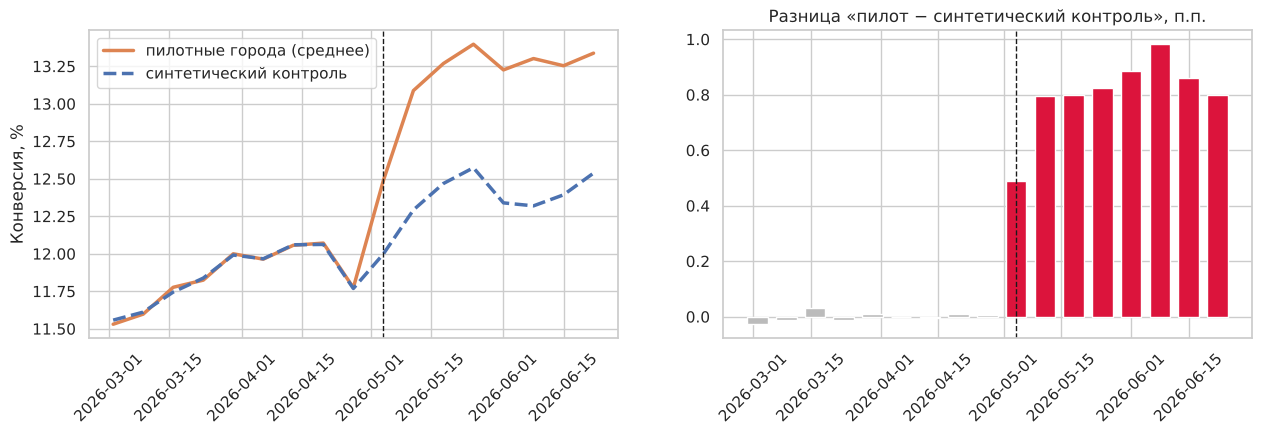

In [18]:
wk_city = (main_df.groupby(["week", "city"])[["orders", "active_users"]].sum()
           .assign(conv=lambda x: 100 * x.orders / x.active_users)["conv"].unstack())
pre_weeks = wk_city.index < LAUNCH
treated_cities = [c for c in city_info.index[city_info.treated == 1] if c != "M02"]
control_cities = list(city_info.index[city_info.treated == 0])


def synth(target, donors):
    X0, x1 = wk_city.loc[pre_weeks, donors].values, target[pre_weeks].values
    k = len(donors)
    res = optimize.minimize(lambda w: np.sum((x1 - X0 @ w) ** 2), np.full(k, 1 / k), method="SLSQP",
                            bounds=[(0, 1)] * k, constraints={"type": "eq", "fun": lambda w: w.sum() - 1})
    return pd.Series(res.x, index=donors), wk_city[donors].values @ res.x


target = wk_city[treated_cities].mean(axis=1)
w_sc, synth_series = synth(target, control_cities)
gap_sc = target - synth_series
sc_est = gap_sc[~pre_weeks].mean()
rmspe = lambda g: np.sqrt(np.mean(g ** 2))
ratio_tr = rmspe(gap_sc[~pre_weeks]) / rmspe(gap_sc[pre_weeks])
ratios = []
for c in control_cities:
    _, s_c = synth(wk_city[c], [d for d in control_cities if d != c])
    g = wk_city[c] - s_c
    ratios.append(rmspe(g[~pre_weeks]) / rmspe(g[pre_weeks]))
p_sc = (1 + np.sum(np.array(ratios) >= ratio_tr)) / (1 + len(ratios))
print("Веса доноров (> 1%):")
print(w_sc[w_sc > 0.01].round(3))
print(f"\nRMSPE до запуска: {rmspe(gap_sc[pre_weeks]):.3f} п.п.")
print(f"Synthetic control: средний эффект после запуска {sc_est:+.3f} п.п. (DiD: {main['est']:+.3f})")
print(f"Placebo-in-space p-value (ранг отношения RMSPE): {p_sc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(wk_city.index, target, lw=2.5, color=PALETTE["treated"], label="пилотные города (среднее)")
axes[0].plot(wk_city.index, synth_series, lw=2.5, ls="--", color=PALETTE["control"], label="синтетический контроль")
axes[1].bar(wk_city.index, gap_sc, width=5, color=np.where(pre_weeks, "#BBBBBB", "crimson"))
for ax in axes:
    ax.axvline(LAUNCH, color="k", ls="--", lw=1)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Конверсия, %")
axes[0].legend()
axes[1].set_title("Разница «пилот − синтетический контроль», п.п.")
show(fig, "10_synthetic_control")

**Наивные оценки против DiD:**
* **До/после в пилотных городах: +1.32 п.п.** — почти в 2 раза больше DiD. В это число входит общий весенний рост:
  в контрольных городах за тот же период конверсия выросла на +0.53 п.п. без всякого алгоритма.
* **Пилотные против контрольных после запуска: +1.07 п.п.** — тоже завышено: пилотные города и до запуска были
  на +0.28 п.п. выше (больше крупных городов). Кроме того, такая оценка смешивает страты с разным эффектом.
* **DiD +0.73 п.п.** вычитает и общий тренд, и постоянную разницу уровней.
  Наивные оценки завысили бы эффект на 45–80%, а экономику раскатки — пропорционально.

**Synthetic control** даёт +0.80 п.п. (DiD +0.73). Синтетический контроль очень точно повторяет пилотные города до
запуска (RMSPE 0.016 п.п.). Placebo-in-space p = 0.077 — это минимально возможное значение при 12 донорах (1/13):
ни один контрольный город не показал такого же расхождения после 4 мая. Независимый метод подтверждает DiD.

### 6.3 Как контролировали сезонность и другие конфаундеры
| Конфаундер | Чем опасен | Как учли |
|---|---|---|
| Недельная сезонность | разное число выходных до/после | фиксированные эффекты даты; окна из целых недель; недельная агрегация (спец. 10) |
| Весенний рост, июньский спад | смешивается с эффектом в сравнении до/после | эффекты даты (общий тренд вычитается) |
| Праздники 9–11 мая, разные по стратам | пилот перекошен в крупные города, где спад сильнее | эффекты «страта × дата»; спецификация без праздников (6) |
| Отбор пилотных городов по размеру | разные уровни и, возможно, разная динамика | эффекты города; сравнение внутри страт; проверка пред-трендов |
| Локальная акция в M02 | ложный рост конверсии | найдена плацебо по городам и исключена |
| Собственные тренды городов | могли бы имитировать эффект | спецификация с линейными трендами городов (4) |
| Сбои логов (S07, L04) | выбросы и пропуски | робастный z-score, исключение дня с дублями |

### 6.4 Итоговая сводка

In [19]:
summary = pd.DataFrame([
    ["Качество данных", "S07: нет 5 дней; L04: дубли заказов 15.04", "день L04 исключён, панель несбалансирована"],
    ["Сезонность", "сильная недельная + праздники, разные по стратам", "FE «страта × дата»"],
    ["Баланс городов", "пилот крупнее (отбор бизнесом); внутри страт |SMD| < 0.1", "сравнение внутри страт"],
    ["Стабильность состава", f"доля DAU пилота p = {p_srm:.2f}; состав без сдвига", "ок"],
    ["Параллельные тренды", f"M02: скачок за 2 недели до запуска; без M02 F-тест p = {wald_main.pvalue:.2f}", "M02 исключён"],
    ["Эффект (основной)", f"{main['est']:+.2f} п.п. [{main['ci_low']:+.2f}; {main['ci_high']:+.2f}], "
                          f"wild p = {p_wild:.3f}, RI p = {p_ri:.4f}", "значим"],
    ["Чувствительность", f"оценки от {sens['est'].min():+.2f} до {sens['est'].max():+.2f} п.п.", "устойчиво"],
    ["Synthetic control", f"{sc_est:+.2f} п.п., p = {p_sc:.3f}", "согласуется"],
], columns=["проверка", "результат", "вывод"]).set_index("проверка")
print(summary.to_string())

                                                                        результат                                       вывод
проверка                                                                                                                     
Качество данных                         S07: нет 5 дней; L04: дубли заказов 15.04  день L04 исключён, панель несбалансирована
Сезонность                       сильная недельная + праздники, разные по стратам                          FE «страта × дата»
Баланс городов           пилот крупнее (отбор бизнесом); внутри страт |SMD| < 0.1                      сравнение внутри страт
Стабильность состава                  доля DAU пилота p = 0.68; состав без сдвига                                          ок
Параллельные тренды   M02: скачок за 2 недели до запуска; без M02 F-тест p = 0.73                                M02 исключён
Эффект (основной)        +0.73 п.п. [+0.41; +1.05], wild p = 0.000, RI p = 0.0008                                     